# SiN Photonic-Crystal Nanocavities I — Band Gaps and Mirrors

Noda, Fujita and Asano's review (*Nat. Photon.* 1, 449 (2007)) shows how photonic-crystal
nanocavities control spontaneous emission: a cavity of quality factor Q and mode volume V
enhances the emission rate of an emitter on resonance by the Purcell factor

$$F = \frac{3}{4\pi^2}\left(\frac{\lambda}{n}\right)^3 \frac{Q}{V}.$$

Their cavities are silicon 2D slab cavities (L3, double heterostructure) with Q ~ 10⁶ in the
near infrared. This series asks how far the same ideas go in **silicon nitride in the visible**,
where emitters such as the NV centre in diamond (zero-phonon line 637 nm) sit and silicon
absorbs. SiN's index (n ≈ 2.0) is much lower than silicon's (3.5), which weakens both the
in-plane band gap and the out-of-plane confinement by total internal reflection. Two cavity
families are compared:

| family | structure | reference designs |
|---|---|---|
| **L3** (2D slab) | three missing holes in a triangular air-hole lattice, end holes shifted outward | Akahane et al., *Nature* 425, 944 (2003); Minkov & Savona, *Sci. Rep.* 4, 5124 (2014) |
| **Nanobeam** (1D) | a row of holes in a narrow ridge, tapered toward the centre | McCutcheon & Lončar, *Opt. Express* 16, 19136 (2008); Quan & Lončar, *Opt. Express* 19, 18529 (2011) |

**Platform:** a suspended 200 nm stoichiometric LPCVD Si₃N₄ membrane in air (the thickness of
the McCutcheon–Lončar design), n = 2.0, design wavelength 637 nm, smallest feature ≥ 50 nm
(e-beam lithography). Sources and their tiers: `sin_cavity/literature.md`.

This notebook prepares both designs from unit-cell band structures (MPB): the guided band gap
of the triangular-lattice slab (L3) and the band edges and mirror strength of one nanobeam
period (nanobeam taper). Notebook 02 builds the L3 cavity, notebook 03 the nanobeam and the
final comparison.

**Model:** 3D, bulk SiN index 2.0 and air, non-dispersive and lossless. This deviates from the
toolkit's 2D effective-index convention: a slab cavity's Q is set by radiation out of the
plane, which a 2D model cannot represent (see `src/pic_toolkit/meep_sim/phc_cavity.py`).
Lengths in µm unless stated, frequencies in c/a (lattice) or c/µm.

**Kernel:** `mp` conda env, run from `sin_cavity/notebooks/`. The band data are produced by
`scripts/slab_gap_map.py` and `scripts/design_nanobeam.py` and cached in `data/`.
**Do not use "Run All."** Run the cells in order and read each result before going on.

## 0. Setup

In [1]:
# Imports, plotting style and cached data locations.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pic_toolkit import style
from pic_toolkit.meep_sim import phc_cavity as pc

style.apply_style()
DATA = Path.cwd().parent / "data"
F_RES = 1 / pc.LAMBDA0            # design frequency, c/um
print(f"n = {pc.N_SIN}, membrane t = {pc.T_SLAB * 1e3:.0f} nm, design wavelength {pc.LAMBDA0 * 1e3:.0f} nm")

n = 2.0, membrane t = 200 nm, design wavelength 637 nm


> **STOP -- the slab gap map is 60 MPB runs (≈ 20 min, `scripts/slab_gap_map.py`), cached in
> `data/bands/slab_gap.npz`.** The cells below only read the cache.

## 1. Triangular air-hole lattice in the SiN membrane

An L3 cavity mode lives inside the band gap of the surrounding lattice. In a slab, only the
part of the band structure **below the light line** (f < |k| in c/a units) is guided; modes
above it leak into the air. The guided TE-like gap (z-even modes, the polarization of the L3
mode) therefore lies between the top of band 1 and the lowest guided point of band 2. Because
the membrane thickness is fixed at 200 nm, t/a changes with the lattice constant, so the gap
was computed for several a as well as r/a.

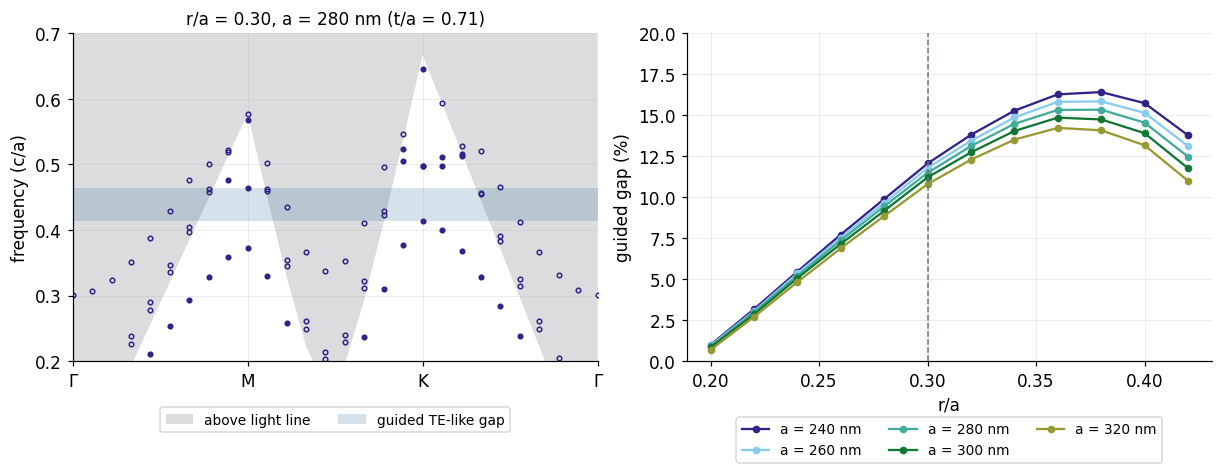

In [2]:
# Bands of one case (left) and the guided gap vs r/a (right).
B = np.load(DATA / "bands" / "slab_gap.npz")
R_A, A_UM, kmag = B["r_a"], B["a_um"], B["kmag"]
i_r, j_a = int(np.argmin(abs(R_A - 0.30))), int(np.argmin(abs(A_UM - 0.28)))
bands = B["bands"][i_r, j_a]                       # (k, band), c/a
lo, hi = B["gap_lo"][i_r, j_a], B["gap_hi"][i_r, j_a]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
kk = np.arange(len(kmag))
ax0.fill_between(kk, kmag, 0.8, color=style.COLOR_REFERENCE, alpha=0.25, lw=0, label="above light line")
ax0.axhspan(lo, hi, color=style.COLOR_STEEL, alpha=0.2, lw=0, label="guided TE-like gap")
for n in range(bands.shape[1]):
    guided = bands[:, n] < kmag
    ax0.plot(kk[guided], bands[guided, n], "o", ms=3, color=style.COLOR_INDIGO)
    ax0.plot(kk[~guided], bands[~guided, n], "o", ms=3, mfc="none", color=style.COLOR_INDIGO)
n_seg = (len(kk) - 1) // 3
ax0.set_xticks([0, n_seg, 2 * n_seg, 3 * n_seg], ["Γ", "M", "K", "Γ"])
ax0.set_xlim(0, len(kk) - 1); ax0.set_ylim(0.2, 0.7)
ax0.set_ylabel("frequency (c/a)")
ax0.set_title(f"r/a = {R_A[i_r]:.2f}, a = {A_UM[j_a] * 1e3:.0f} nm (t/a = {pc.T_SLAB / A_UM[j_a]:.2f})", fontsize=11)
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)

for j, a in enumerate(A_UM):
    gap = 200 * (B["gap_hi"][:, j] - B["gap_lo"][:, j]) / (B["gap_hi"][:, j] + B["gap_lo"][:, j])
    ax1.plot(R_A, gap, "o-", color=style.COLOR_CYCLE[j], ms=4, label=f"a = {a * 1e3:.0f} nm")
ax1.axvline(0.30, color=style.COLOR_REFERENCE, ls="--", lw=1)
ax1.set_xlabel("r/a"); ax1.set_ylabel("guided gap (%)"); ax1.set_ylim(0, 20)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
fig.savefig(DATA / "fig_slab_bands.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
# Gap edges at r/a = 0.30 in wavelength: which lattice constant puts 637 nm inside the gap.
for j, a in enumerate(A_UM):
    l_hi, l_lo = a / B["gap_lo"][i_r, j] * 1e3, a / B["gap_hi"][i_r, j] * 1e3
    print(f"a = {a * 1e3:.0f} nm: gap {B['gap_lo'][i_r, j]:.4f}-{B['gap_hi'][i_r, j]:.4f} c/a "
          f"= {l_lo:.0f}-{l_hi:.0f} nm" + ("  <- contains 637 nm" if l_lo < 637 < l_hi else ""))

a = 240 nm: gap 0.4040-0.4559 c/a = 526-594 nm
a = 260 nm: gap 0.4091-0.4603 c/a = 565-636 nm
a = 280 nm: gap 0.4136-0.4640 c/a = 603-677 nm  <- contains 637 nm
a = 300 nm: gap 0.4188-0.4686 c/a = 640-716 nm
a = 320 nm: gap 0.4239-0.4723 c/a = 678-755 nm


Filled points are guided, open points lie above the light line. The guided gap grows from ≈ 1 % at
r/a = 0.20 to 16 % near r/a ≈ 0.36–0.38, and shrinks slowly as a grows (the membrane becomes thinner in
units of a). Much of the band structure near Γ sits above the light line: with n = 2.0 the
light cone takes a large share of k-space, which is what limits the Q of a SiN slab cavity.

The L3 design uses **r/a = 0.30**, which keeps an 11–12 % gap while leaving walls of 0.4a
(≈ 110 nm) between neighbouring holes, well above the 50 nm e-beam limit. Removing holes adds
dielectric, so the L3 defect mode is pulled down from the air band and sits in the lower part of
the gap (f ≈ 0.415 c/a, notebook 02). With a = 266.6 nm, chosen in notebook 02 from the
resonance itself, the gap spans ≈ 580–650 nm and the mode lands at 642 nm.

> **STOP -- 11 MPB runs of one nanobeam period (≈ 3 min, `scripts/design_nanobeam.py`),
> cached in `data/nanobeam/design_band_edges.npz`.**

## 2. Nanobeam unit cell: band edges and mirror strength

A nanobeam cavity is a Bragg mirror in a ridge waveguide (300 nm × 200 nm). One period of
length a = 250 nm with a hole of radius r has a TE-like band gap at the X point (k = π/a)
between the dielectric band edge f₁ and the air band edge f₂. Quan & Lončar define the
**mirror strength** at the resonance frequency f_res,

$$\gamma = \sqrt{\left(\frac{f_2 - f_1}{f_2 + f_1}\right)^2 - \left(\frac{f_{res} - f_0}{f_0}\right)^2}, \qquad f_0 = \frac{f_1 + f_2}{2},$$

the decay constant of the field per period inside the mirror (γ = 0 when f_res lies outside the
gap). Their recipe fixes two radii from this map:
- the **centre radius r_c**, where the dielectric band edge equals f_res — the cavity mode
  forms from that band edge;
- the **mirror radius r_m**, where γ is largest.

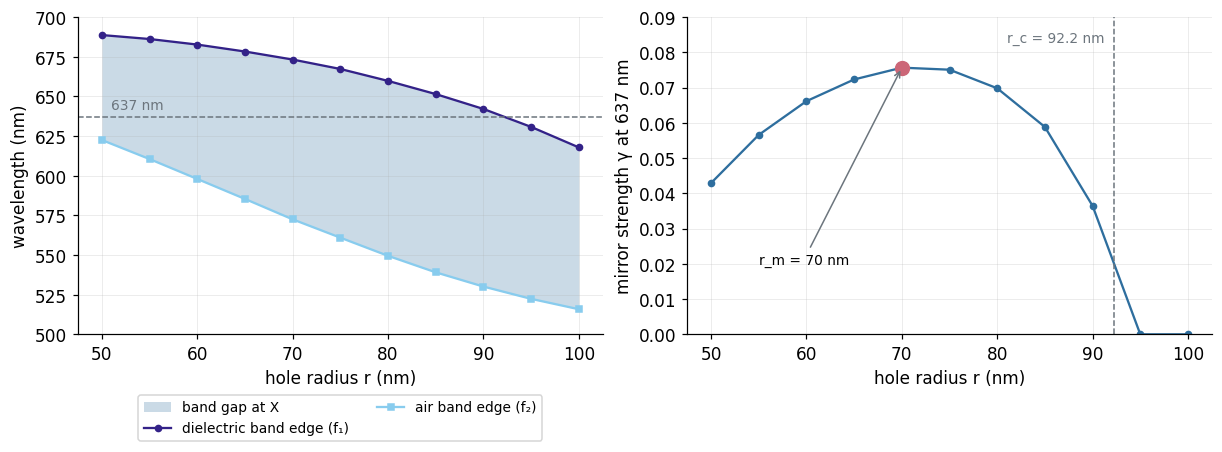

r_c = 92.2 nm (f1 = f_res), r_m = 70 nm (gamma = 0.076), gap at r_m: 572-673 nm


In [4]:
# Band edges (in nm) and mirror strength at 637 nm vs hole radius.
E = np.load(DATA / "nanobeam" / "design_band_edges.npz")
r_nm, f1, f2, gam = E["r"] * 1e3, E["f1"], E["f2"], E["gamma"]
r_c = float(np.interp(F_RES, f1, E["r"])) * 1e3      # f1 rises with r
r_m = float(r_nm[np.argmax(gam)])

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ax0.fill_between(r_nm, 1e3 / f2, 1e3 / f1, color=style.COLOR_STEEL, alpha=0.25, lw=0, label="band gap at X")
ax0.plot(r_nm, 1e3 / f1, "o-", ms=4, color=style.COLOR_INDIGO, label="dielectric band edge (f₁)")
ax0.plot(r_nm, 1e3 / f2, "s-", ms=4, color=style.COLOR_CYAN, label="air band edge (f₂)")
ax0.axhline(637, color=style.COLOR_REFERENCE, ls="--", lw=1)
ax0.text(51, 640, "637 nm", color=style.COLOR_REFERENCE, fontsize=9, va="bottom")
ax0.set_xlabel("hole radius r (nm)"); ax0.set_ylabel("wavelength (nm)"); ax0.set_ylim(500, 700)
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)

ax1.plot(r_nm, gam, "o-", ms=4, color=style.COLOR_STEEL)
ax1.plot([r_m], [gam.max()], "o", ms=9, color=style.COLOR_ROSE)
ax1.axvline(r_c, color=style.COLOR_REFERENCE, ls="--", lw=1)
ax1.annotate(f"r_m = {r_m:.0f} nm", (r_m, gam.max()), (55, 0.02), fontsize=9,
             arrowprops=dict(arrowstyle="->", color=style.COLOR_REFERENCE))
ax1.text(r_c - 1, 0.083, f"r_c = {r_c:.1f} nm", ha="right", fontsize=9, color=style.COLOR_REFERENCE)
ax1.set_xlabel("hole radius r (nm)"); ax1.set_ylabel("mirror strength γ at 637 nm"); ax1.set_ylim(0, 0.09)
fig.savefig(DATA / "fig_nanobeam_mirror.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"r_c = {r_c:.1f} nm (f1 = f_res), r_m = {r_m:.0f} nm (gamma = {gam.max():.3f}), "
      f"gap at r_m: {1e3 / f2[np.argmax(gam)]:.0f}-{1e3 / f1[np.argmax(gam)]:.0f} nm")

The mirror is strongest at r = 70 nm (r/a = 0.28), exactly the mirror hole of the
McCutcheon–Lončar design: 637 nm then sits near mid-gap (572–673 nm). The gap is only
≈ 16 % of the mid-gap frequency, so the field decays slowly inside the mirror and SiN
nanobeams need many mirror periods (17 in McCutcheon & Lončar).

## 3. Taper designs

Two tapers bring the field from the cavity centre into the mirror:

- **McCutcheon & Lončar (reproduction target).** Four holes whose period and radius both
  shrink toward the centre, (a, r) = (250, 66) → (238, 62) → (226, 58) → (214, 55) nm, a
  cavity gap s between the two innermost holes, and 17 mirror periods (a = 250, r = 70 nm).
- **Own design (Quan–Lončar recipe).** Constant period a = 250 nm, zero cavity length
  (innermost holes at ±a/2), hole filling fraction πr²/(aw) tapered quadratically from r_c to
  r_m over N segments, then 10 mirror holes at r_m. A quadratic filling fraction makes γ
  rise about linearly away from the centre, which gives a Gaussian field envelope and
  suppresses the momentum components inside the light cone. N = 15 and 20 are compared.

McCutcheon & Lončar (s = 95 nm): 21 holes per side, beam length 10.24 um, inner hole r = 55.0 nm at x = 103 nm
own, N = 15: 26 holes per side, beam length 12.89 um, inner hole r = 92.2 nm at x = 125 nm
own, N = 20: 31 holes per side, beam length 15.39 um, inner hole r = 92.2 nm at x = 125 nm


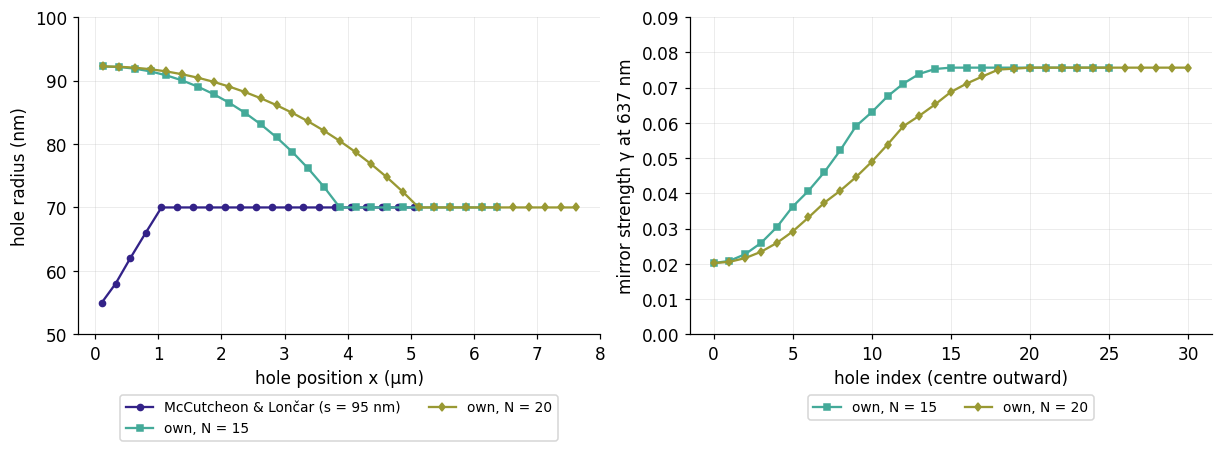

In [5]:
# Hole radius vs position (x > 0, centre outward) for the three designs, and the mirror strength
# each hole of the own designs would have as a uniform mirror (gamma(r) from Section 2).
mc = pc.MCCUTCHEON
designs = {
    "McCutcheon & Lončar (s = 95 nm)": pc.nanobeam_holes(mc["taper"], mc["mirror"], mc["n_mirror"], 0.095, "edge"),
    "own, N = 15": np.load(DATA / "nanobeam" / "design_N15.npy"),
    "own, N = 20": np.load(DATA / "nanobeam" / "design_N20.npy"),
}
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for (name, h), c, m in zip(designs.items(), style.COLOR_CYCLE[::2], "osd"):
    ax0.plot(h[:, 0], h[:, 1] * 1e3, m + "-", ms=4, color=c, label=name)
    print(f"{name}: {len(h)} holes per side, beam length {2 * (h[-1, 0] + h[-1, 1]):.2f} um, "
          f"inner hole r = {h[0, 1] * 1e3:.1f} nm at x = {h[0, 0] * 1e3:.0f} nm")
    if name.startswith("own"):
        ax1.plot(np.arange(len(h)), np.interp(h[:, 1], E["r"], gam), m + "-", ms=4, color=c, label=name)
ax0.set_xlabel("hole position x (µm)"); ax0.set_ylabel("hole radius (nm)"); ax0.set_ylim(50, 100)
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)
ax1.set_xlabel("hole index (centre outward)"); ax1.set_ylabel("mirror strength γ at 637 nm")
ax1.set_ylim(0, 0.09)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)
fig.savefig(DATA / "fig_nanobeam_tapers.png", dpi=150, bbox_inches="tight")
plt.show()

The McCutcheon taper is short (four holes) and changes both a and r; the own designs keep a
fixed and spread the taper over 15 or 20 holes, so their mirror strength climbs smoothly from
near zero at the centre (γ is interpolated on the 5 nm grid of Section 2, hence the small
non-zero start) to the full γ ≈ 0.076, roughly linearly over the middle of the taper. The cost is length: about 13–15 µm
instead of ≈ 10 µm, still well within a single suspended membrane.

## 4. Summary

- The guided TE-like gap of a triangular hole lattice in a 200 nm SiN membrane grows from
  ≈ 1 % at r/a = 0.20 to 14–16 % at r/a ≈ 0.36–0.38 (a 240–320 nm), and is 11–12 % at r/a = 0.30. The L3 design uses
  r/a = 0.30 and a ≈ 267 nm (notebook 02).
- A 300 nm × 200 nm SiN nanobeam with a = 250 nm has its strongest mirror at r = 70 nm
  (γ = 0.076, gap 572–673 nm), the McCutcheon–Lončar mirror hole. The dielectric band edge
  reaches 637 nm at r = 92 nm, the centre hole of the own Quan–Lončar taper.
- The two nanobeam tapers (McCutcheon's 4-hole taper and the own 15/20-hole quadratic taper)
  are simulated in 3D in notebook 03.